In [3]:
import numpy as np
import discretisedfield as df
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import os 
from matplotlib.colors import hsv_to_rgb
import matplotlib.patches as patches
import matplotlib as mpl
from scripts.read_field import file_to_array, read_dir, draw_field, animate_field, spirality 
from scripts.mm.fit import fit
from scripts.mm.experiment import Experiment
import scripts.scientific 

mpl.rcParams.update(mpl.rcParamsDefault)

In [6]:
def topological_charge(m, dx=1.0, dy=1.0):
    dmdx = np.gradient(m, dx, axis=2)
    dmdy = np.gradient(m, dy, axis=1)
    cross = np.cross(dmdy, dmdx)
    density = np.sum(m * cross, axis=-1)
    Q = np.round(np.sum(density, axis=(1, 2)) * dx * dy / (4 * np.pi), 10)
    return Q

## Template

In [9]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif"
})

In [107]:
from cmap import Colormap
def draw(data, frames, times, cutoff = 1, profile = False, charge = False, spirality=True):
    cmap = Colormap('colorcet:cet_cbtc2').to_mpl()
    fig, axs = plt.subplots(2,len(frames), figsize=(9/4 * len(frames),3.7), sharey='row', sharex='col',  gridspec_kw={'height_ratios': [3, 1]})
    # fig, axs = plt.subplots(2,4, figsize=(9,3), sharey='row',  gridspec_kw={'height_ratios': [3, 1]})
    fig.tight_layout()

    _data = np.concat([[data[frame]] for frame in frames])
    data = _data 
    middle = data.shape[1] // 2
    charges = [round(Q,2) for Q in topological_charge(data)]
    size = (data.shape[1] - 2 * cutoff) * 0.025 / 2
    x = np.linspace(-size, size, data.shape[1] - 2 * cutoff)

    for i, d in enumerate(data):
        axs[0][i].set_title(f"${times[i] if times[i] != 1 else ''} t_0$" + (f"$, Q={'{:.2f}'.format(charges[i])}$" if charge else ""), fontsize=12)
        draw_field(axs[0][i], d, mode='spirality', cutoff=cutoff, spirality_contrast=2 if spirality else 200)
        if (profile):
            axs[1][i].plot(x, d[middle,cutoff:-cutoff, 2])

    for i, ax in enumerate(axs[0]):
        ax.set_xticks([-1,0,1])
        ax.set_yticks([-1,0,1])

    axs[1][len(frames) - 1].yaxis.set_label_position("right")
    axs[1][len(frames) - 1].set_ylabel("$m_z$")

    for i, ax in enumerate(axs[1]):
        ax.set_yticks([1,0,-1])
        ax.yaxis.set_inverted(True)
        if not profile:
            ax.remove()

    plt.subplots_adjust(wspace=0.07, hspace=0.07, bottom=0.2)
    if not profile:
        plt.subplots_adjust(bottom=-0.4)
    # plt.show()

(18, 560, 560, 3)


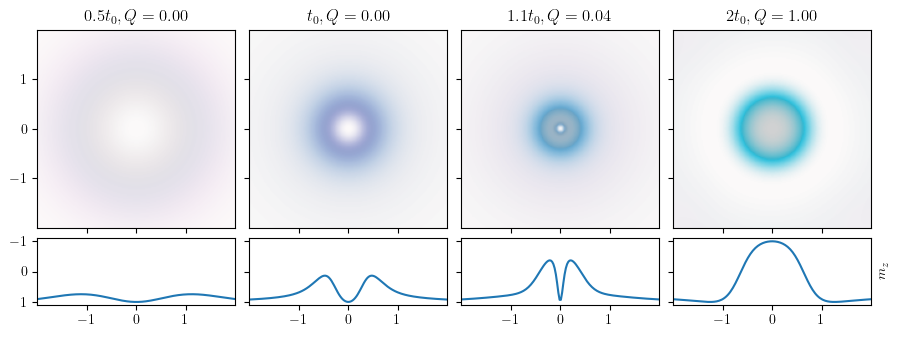

In [151]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-62-example-create-regular-swing-start', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-63-example-create-regular-swing-end', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-65-example-create-regular-swing-end-prolonged', delete_files=False, new_name=None, scaling=1e5),
])
print(data.shape)
draw(data, frames=[2, 3, 8, 16], times=[0.5, 1, 1.1, 2], cutoff=200, profile=True, charge=True)
plt.savefig("./article/images/example_create_swing.pdf")

(22, 560, 560, 3)


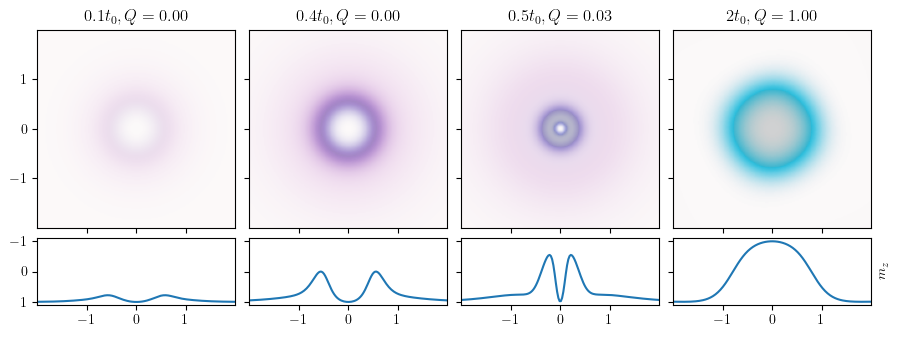

In [172]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-64-example-create-regular-direct', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-71-drive-64-example-create-regular-direct-prolonged', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-66-example-create-regular-stable', delete_files=False, new_name=None, scaling=1e5)
    
])

print(data.shape)
draw(data, frames=[2, 8, 10, -2], times=[0.1, 0.4, 0.5, 2], cutoff=200, profile=True, charge=True)
plt.savefig("./article/images/example_create_direct.pdf")

(14, 560, 560, 3)


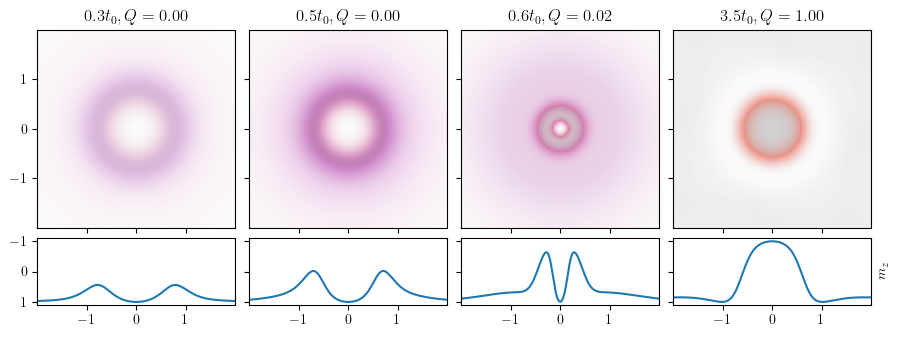

In [150]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-74-example-create-negative-direct', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-79-example-create-negative-direct-prolonged', delete_files=False, new_name=None, scaling=1e5),
])
print(data.shape)
draw(data, frames=[1, 2, 3, 13], times=[0.3, 0.5, 0.6, 3.5], cutoff=200, profile=True, charge=True)
plt.savefig("./article/images/example_create-negative-direct.pdf")

(8, 400, 400, 3)


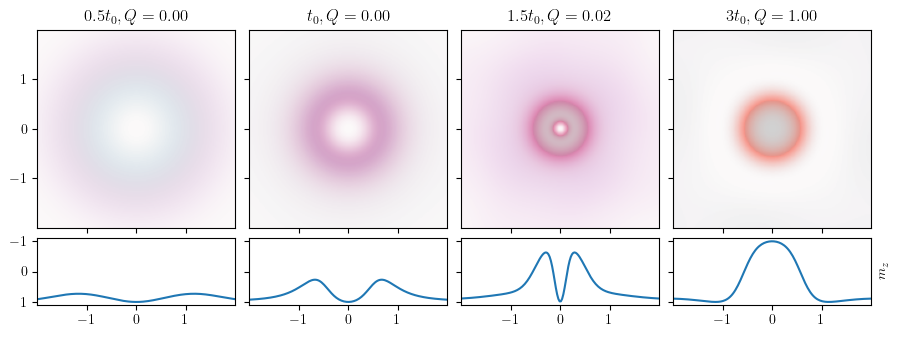

In [144]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-76-example-create-negative-swing-start', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-77-example-create-negative-swing-end', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-78-example-create-negative-swing-end-prolonged', delete_files=False, new_name=None, scaling=1e5),
])
print(data.shape)
draw(data, frames=[1,3,4,7], times=[0.5, 1, 1.5, 3], cutoff=120, profile=True, charge=True)
plt.savefig("./article/images/example_create-negative-swing.pdf")

(22, 560, 560, 3)


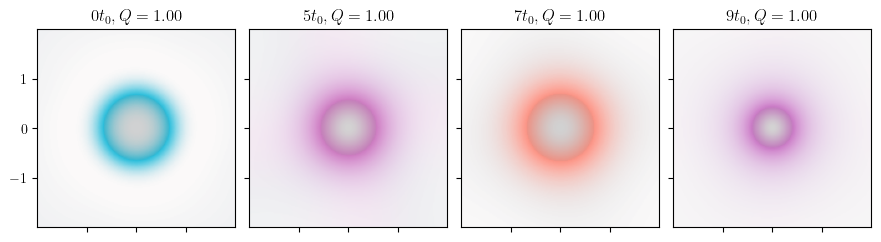

In [255]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-66-example-create-regular-stable', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-70-example-regular-destory', delete_files=False, new_name=None, scaling=1e5),
])
print(data.shape)
draw(data, frames=[0, 5, 7, 9], times=[0, 5, 7, 9], cutoff=200, charge=True)
plt.savefig("./article/images/example_destroy-1.pdf")

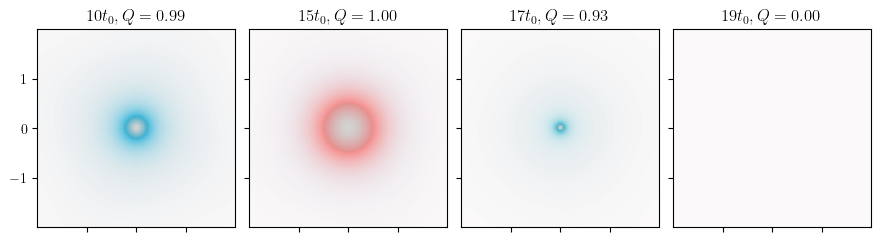

In [257]:
draw(data, frames=[10, 14, 16, 18], times=[10, 15, 17, 19], cutoff=200, charge=True)
plt.savefig("./article/images/example_destroy-2.pdf")

(11, 560, 560, 3)


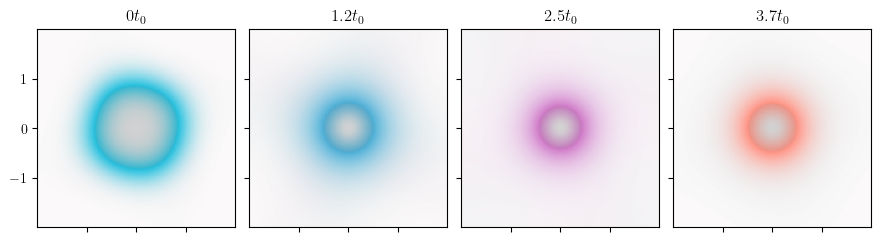

In [36]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-72-example-chirality-switch-swing-end', delete_files=False, new_name=None, scaling=1e5),
])
print(data.shape)
draw(data, frames=[0,1,2,4], times=[0, 1.2,2.5, 3.7], cutoff=200)
plt.savefig('./article/images/example-chirality-switch.pdf')

(22, 560, 560, 3)


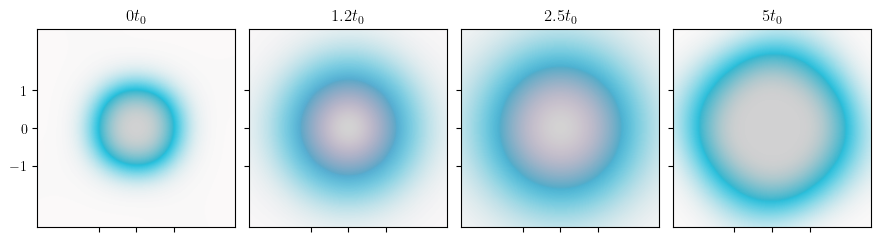

In [87]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-85-example-enlarge', delete_files=False, new_name=None, scaling=1e5),
])
print(data.shape)
draw(data, frames=[0,5,10,21], times=[0, 1.2,2.5, 5], cutoff=175)
plt.savefig('./article/images/example-inflate.pdf')

(19, 560, 560, 3)


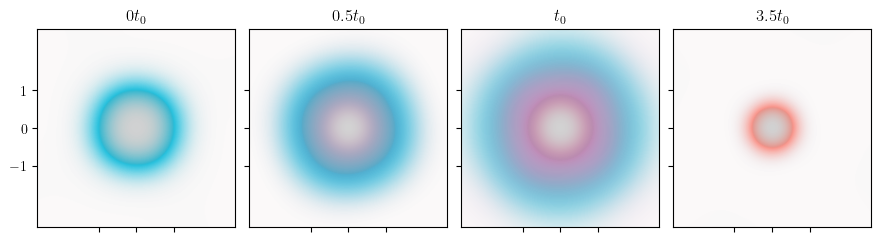

In [106]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-90-example-switch', delete_files=False, new_name=None, scaling=1e5),
])
print(data.shape)
draw(data, frames=[0,2,4,18], times=[0, 0.5,1, 3.5], cutoff=175)
plt.savefig('./article/images/example-switch-instead-inflation.pdf')

(58, 560, 560, 3)


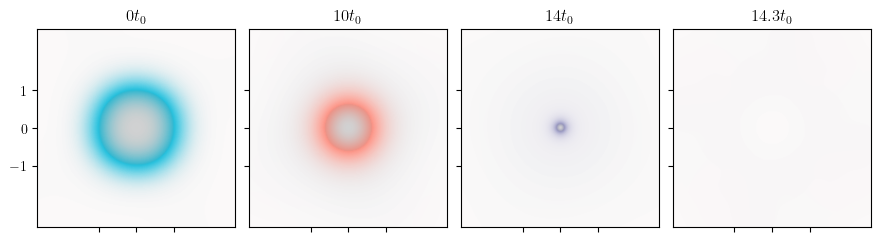

In [104]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-84-example-switch', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-91-example-switch-continue', delete_files=False, new_name=None, scaling=1e5)[1:],
])
print(data.shape)
draw(data, frames=[0,40,56,57], times=[0,10,14, 14.3], cutoff=175)
plt.savefig('./article/images/example-destroy-instead-inflation.pdf')




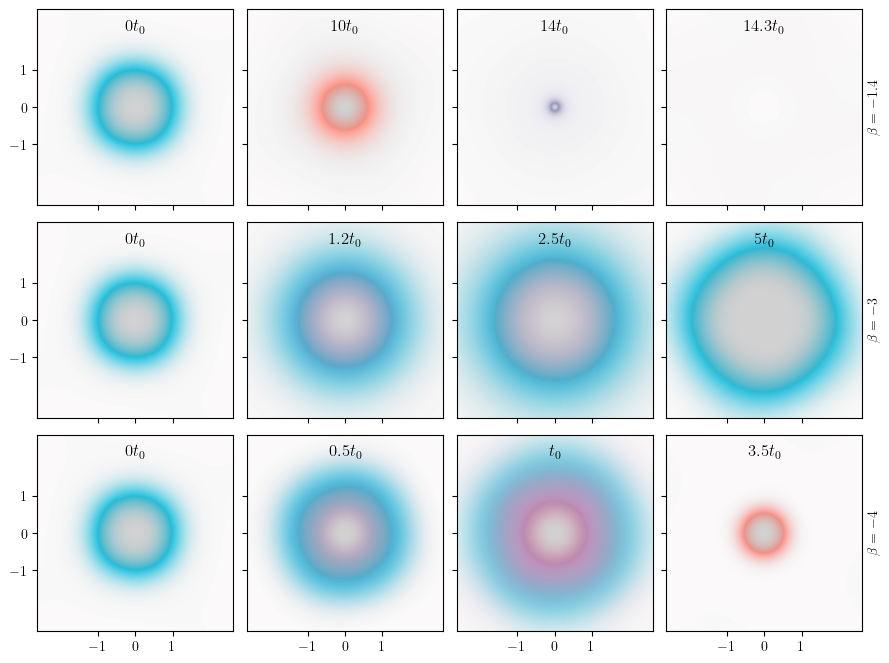

In [125]:
data_inflate = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-85-example-enlarge', delete_files=False, new_name=None, scaling=1e5),
])
frames_inflate = [0,5,10,21]
times_inflate = [0, 1.2,2.5, 5]

data_switch = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-90-example-switch', delete_files=False, new_name=None, scaling=1e5),
])
frames_switch =[0,2,4,18]
times_switch = [0, 0.5,1, 3.5]

data_destroy = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-84-example-switch', delete_files=False, new_name=None, scaling=1e5),
    read_dir('./04-creation/skyrmion_system/drive-91-example-switch-continue', delete_files=False, new_name=None, scaling=1e5)[1:],
])
frames_destroy = [0,40,56,57]
times_destroy=[0,10,14, 14.3]

fig, axs = plt.subplots(3,4, figsize=(9/4 * 4,3 * 9 /4), sharey='row', sharex='col')
fig.tight_layout()

for row, collection in enumerate([
    [data_destroy, frames_destroy, times_destroy],
    [data_inflate, frames_inflate, times_inflate],
    [data_switch, frames_switch, times_switch],
]):
    for col, frame in enumerate(collection[1]):
        axs[row,col].set_title(f"${collection[2][col] if collection[2][col] != 1 else ''} t_0$", fontsize=12, y=0.85)
        draw_field(axs[row, col], collection[0][frame], mode='spirality', cutoff=175, spirality_contrast=2)

for row in range(3):
    axs[row, 0].set_yticks([-1,0,1])
    axs[row, -1].set_ylabel(f"$\\beta={[-1.4, -3, -4][row]}$")
    axs[row, -1].yaxis.set_label_position("right")
for col in range(4):
    axs[-1, col].set_xticks([-1,0,1])

fig.tight_layout()
plt.subplots_adjust(wspace=0.07, hspace=0.07)

plt.savefig('./article/images/example-destroy-inflate-switch.pdf')


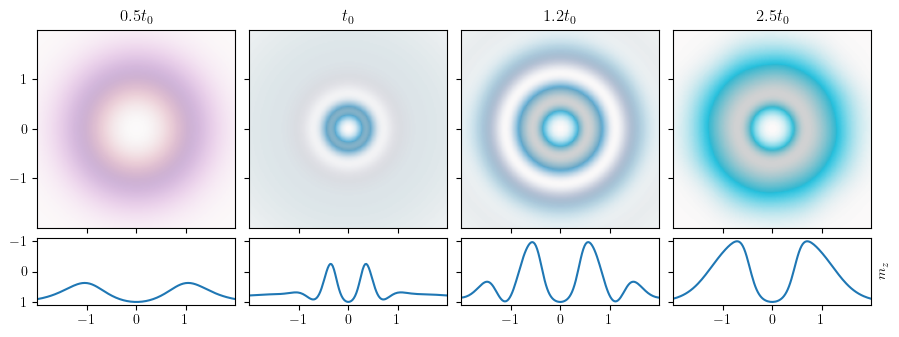

In [169]:
data = np.concat([
    read_dir('./04-creation/skyrmion_system/drive-96-example-skyrmionium-swing-start', delete_files=False, new_name=None, scaling=1e5),
    # read_dir('./04-creation/skyrmion_system/drive-98-example-skyrmionium-swing-end-detailed', delete_files=False, new_name=None, scaling=1e5)[1:],
    read_dir('./04-creation/skyrmion_system/drive-97-example-skyrmionium-swing-end', delete_files=False, new_name=None, scaling=1e5)[1:],
])
draw(data, frames=[2,5,6,10], times=[0.5,1,1.2,2.5], cutoff=200, profile=True)
plt.savefig('./article/images/example-create-skyrmionium.pdf')
